# Rb85 qubit states — Feshbach fields first, then sensitivity and closedness

Rb85 turns the qubit question of `qubit_states_rb87.ipynb` on its head. In
Rb87 the background scattering length is positive, the BEC is stable at any
field, and you park the field on a magic point of your favourite pair. In
**Rb85 every low-field channel has a large negative background scattering
length** ($a_{bg} \approx -400\,a_0$; an attractive condensate collapses
beyond $N_{cr} \sim 0.57\, a_{ho}/|a|$, i.e. a few hundred atoms), so a BEC
exists **only where a Feshbach resonance tunes $a > 0$**. The magnetic field
is therefore *not free* — it is pinned to a narrow window next to a
resonance, and the qubit must be judged **at that field**.

The plan:

1. **The Feshbach resonances of Rb85** — the broad, usable ones from the
   literature, the $a(B)$ they produce, and the windows where $a > 0$.
2. **Breit–Rabi** structure of $5S_{1/2}$ ($I = 5/2$, $F = 2, 3$) with those
   windows marked.
3. **Closedness** — which pairs of sublevels are stable against two-body
   spin-exchange at the BEC field.
4. **Sensitivity** $d\nu/dB$ of the candidate qubit transitions inside each
   window.
5. **Magic points** — all of them, and whether any coincide with a usable
   Feshbach window.
6. The $|2,+2\rangle$ (absolute ground state) route, and a summary.

> `kamo.scattering` (potentials, coupled channels) is **39K only**, so the
> resonance parameters here are literature values, hard-coded below:
> Claussen *et al.*, PRA **67**, 060701 (2003) for the 155 G resonance, and
> Blackley *et al.*, PRA **87**, 033611 (2013) for the rest.

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt

from kamo import atom as make_atom
from kamo.hamiltonian import AtomicStructure

plt.rcParams["figure.figsize"] = (7, 4.2)
plt.rcParams["figure.dpi"] = 100

rb85 = make_atom("Rb85")
print(rb85, "  I =", rb85.I, "  gI =", rb85.gI)
print(rb85.hyperfine_constants(5, 0, 0.5))

model = AtomicStructure([(5, 0, 0.5)], atom=rb85)
res = model.magnetic_sweep(B_max=900.0, dB=0.05)
B = res.param
print("basis: 12 states, F = 2 (lower) and F = 3 (upper); hyperfine splitting",
      f"{res.get_transition_frequency((5,0,0.5,2,0), (5,0,0.5,3,0), at=0.0)/1e9:.6f} GHz")

Rubidium85(use_portal=True, portal_species='Rb1')   I = 2.5   gI = -0.00029364
5s1/2: A = 1011.91081 MHz [portal (measured)], B = 0 MHz [exact (J = 1/2)]


basis: 12 states, F = 2 (lower) and F = 3 (upper); hyperfine splitting 3.035732 GHz


## 1. The Feshbach resonances that matter

Near an isolated resonance $a(B) = a_{bg}\,[1 - \Delta/(B - B_0)]$. With
$a_{bg} < 0$ the window where $a > 0$ lies **between $B_0$ and $B_0 + \Delta$**
(on the side of $B_0$ that $\Delta$'s sign points to) and is only $|\Delta|$
wide. The broad (usable) resonances of Rb85:

| channel | $B_0$ (G) | $\Delta$ (G) | $a_{bg}$ ($a_0$) | source |
|---|---|---|---|---|
| $\|2,-2\rangle{+}\|2,-2\rangle$ | 155.041 | +10.71 | −443 | Claussen 2003 (the JILA BEC resonance) |
| $\|2,-2\rangle{+}\|2,-2\rangle$ | 532.3 | +2.3 | −474 | Blackley 2013 |
| $\|2,+2\rangle{+}\|2,+2\rangle$ | 852.3 | −1.2 | −393 | Blackley 2013 |

Blackley *et al.* list many more resonances in both channels
(e.g. $|2,-2\rangle$: 219.6, 232.3, 248.6, 297.4, 604.1 G ...), but with
widths of **millligauss**, far too narrow to hold a condensate at a
controlled $a$; they are left out of the model below. All Rb85 BEC work to
date uses the 155 G resonance.

In [2]:
a0 = 1.0   # scattering lengths below are in units of a0 already

RESONANCES = {
    "ee 155":  dict(channel="|2,-2>+|2,-2>", B0=155.041, Delta=+10.71, abg=-443.0),
    "ee 532":  dict(channel="|2,-2>+|2,-2>", B0=532.3,   Delta=+2.3,   abg=-474.0),
    "aa 852":  dict(channel="|2,+2>+|2,+2>", B0=852.3,   Delta=-1.2,   abg=-393.0),
}

def a_of_B(Bf, B0, Delta, abg):
    return abg * (1.0 - Delta / (Bf - B0))

def positive_window(B0, Delta):
    lo, hi = sorted((B0, B0 + Delta))
    return lo, hi

for name, r in RESONANCES.items():
    lo, hi = positive_window(r["B0"], r["Delta"])
    print(f"{name}  {r['channel']}: a > 0 for {lo:.2f} G < B < {hi:.2f} G "
          f"(width {abs(r['Delta']):.2f} G)")

ee 155  |2,-2>+|2,-2>: a > 0 for 155.04 G < B < 165.75 G (width 10.71 G)
ee 532  |2,-2>+|2,-2>: a > 0 for 532.30 G < B < 534.60 G (width 2.30 G)
aa 852  |2,+2>+|2,+2>: a > 0 for 851.10 G < B < 852.30 G (width 1.20 G)


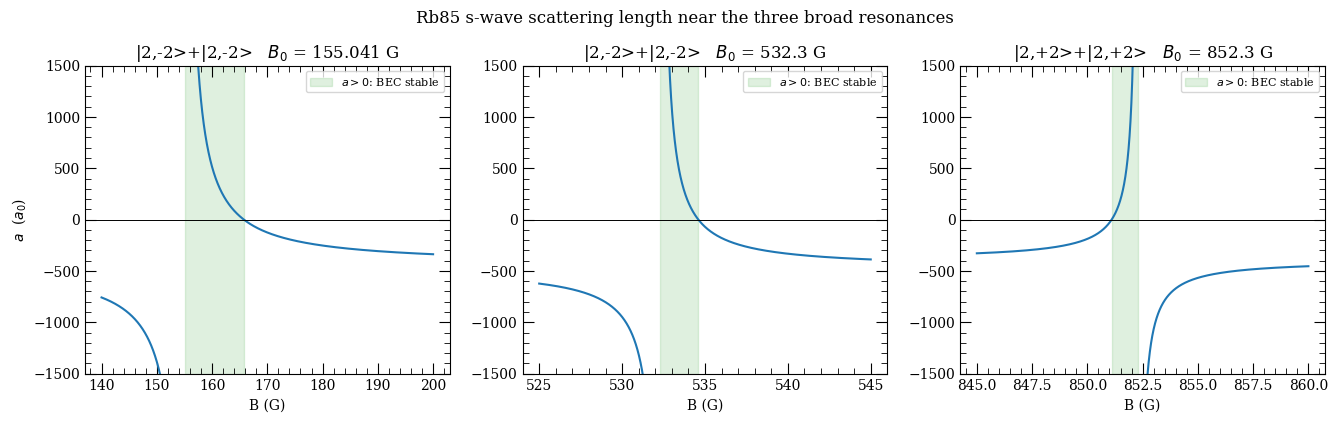

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.0))
spans = [(140, 200), (525, 545), (845, 860)]
for axi, (name, r), (blo, bhi) in zip(ax, RESONANCES.items(), spans):
    Bf = np.linspace(blo, bhi, 4000)
    a = a_of_B(Bf, r["B0"], r["Delta"], r["abg"])
    a[np.abs(Bf - r["B0"]) < 0.02] = np.nan
    axi.plot(Bf, a)
    axi.axhline(0, color="k", lw=0.7)
    lo, hi = positive_window(r["B0"], r["Delta"])
    axi.axvspan(lo, hi, color="tab:green", alpha=0.15, label="$a > 0$: BEC stable")
    axi.set_ylim(-1500, 1500)
    axi.set_xlabel("B (G)"); axi.set_title(f"{r['channel']}   $B_0$ = {r['B0']} G")
    axi.legend(fontsize=8)
ax[0].set_ylabel("$a$  ($a_0$)")
fig.suptitle("Rb85 s-wave scattering length near the three broad resonances", y=1.02);

In [4]:
print("a(B) in the |2,-2> windows (a0):")
for Bq in [155.5, 156.0, 158.0, 160.0, 162.0, 164.0, 165.0, 165.5]:
    r = RESONANCES["ee 155"]
    print(f"   B = {Bq:6.1f} G:  a = {a_of_B(Bq, r['B0'], r['Delta'], r['abg']):+8.0f}")
print()
for Bq in [532.5, 533.0, 533.5, 534.0, 534.5]:
    r = RESONANCES["ee 532"]
    print(f"   B = {Bq:6.1f} G:  a = {a_of_B(Bq, r['B0'], r['Delta'], r['abg']):+8.0f}")
print()
print("typical Rb85 BEC operating points: a ~ +100...+500 a0, i.e. B ~ 160-165 G")

a(B) in the |2,-2> windows (a0):
   B =  155.5 G:  a =    +9894
   B =  156.0 G:  a =    +4504
   B =  158.0 G:  a =    +1160
   B =  160.0 G:  a =     +514
   B =  162.0 G:  a =     +239
   B =  164.0 G:  a =      +87
   B =  165.0 G:  a =      +33
   B =  165.5 G:  a =      +11

   B =  532.5 G:  a =    +4977
   B =  533.0 G:  a =    +1083
   B =  533.5 G:  a =     +434
   B =  534.0 G:  a =     +167
   B =  534.5 G:  a =      +22

typical Rb85 BEC operating points: a ~ +100...+500 a0, i.e. B ~ 160-165 G


## 2. Breit–Rabi with the Feshbach windows marked

$I = 5/2$: $F = 2$ (5 states, **lower** manifold, $g_F = -1/3$) and $F = 3$
(7 states, $g_F = +1/3$), split by 3.036 GHz. Note that $|2,-2\rangle$ —
the Feshbach/BEC state — rises with field ($g_F m_F > 0$): it is a low-field
seeker (magnetically trappable, historically how JILA held it), **not** the
absolute ground state; $|2,+2\rangle$ is.

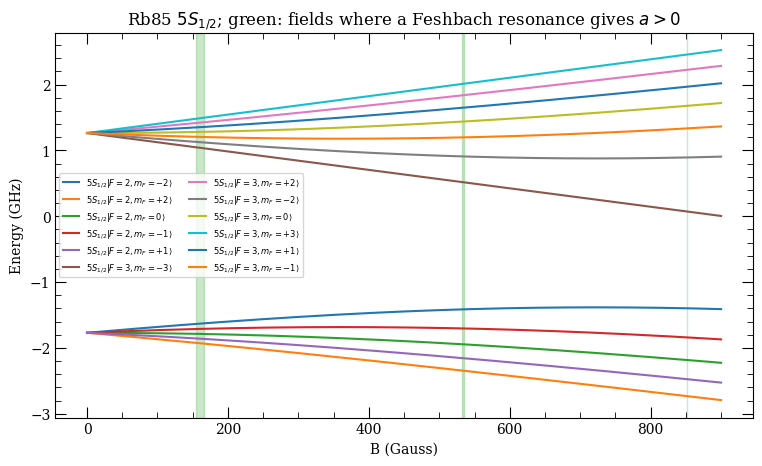

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
res.plot(ax=ax, states=(5, 0, 0.5), coupled_labels=True, energy_unit="GHz")
for name, r in RESONANCES.items():
    lo, hi = positive_window(r["B0"], r["Delta"])
    ax.axvspan(lo, hi, color="tab:green", alpha=0.25)
ax.set_title("Rb85 $5S_{1/2}$; green: fields where a Feshbach resonance gives $a > 0$")
ax.legend(fontsize=6, ncol=2);

## 3. Closedness at the BEC field

Spin-exchange collisions conserve $m_{F,\mathrm{tot}}$; a pair channel is
**closed** if no channel with the same $m_{F,\mathrm{tot}}$ lies lower at the
operating field. Unlike Rb87, Rb85 has **no protective coincidence of
scattering lengths** ($a_s \approx +2700\,a_0$ from a near-threshold singlet
bound state, $a_t \approx -390\,a_0$), so an energetically open channel
really does decay fast — closedness is a hard requirement here, not a
nicety.

Three useful facts the check below confirms at 160 G:

* $|2,-2\rangle{+}|2,-2\rangle$ is closed: within $F{=}2 \otimes F{=}2$ no
  other pair reaches $m_{F,\mathrm{tot}} = -4$, and $F{=}3$ channels are
  3 GHz uphill. (This is why the Rb85 BEC exists at all.)
* The Breit–Rabi quadratic shift makes $E(m_F)$ **convex** within the lower
  manifold, so *all* $F{=}2$ pairs are protected against spreading
  ($2\,E(m_F) < E(m_F{-}1) + E(m_F{+}1)$).
* Among $F{=}3$ partners for the qubit, only the stretched $|3,-3\rangle$
  survives: $|2,-2\rangle{+}|3,-3\rangle$ has $m_{F,\mathrm{tot}} = -5$,
  unreachable by any lower pair. A partner like $|3,-2\rangle$ is killed by
  $|2,-2\rangle{+}|3,-2\rangle \to |2,-2\rangle{+}|2,-2\rangle$
  (−3 GHz exothermic).

Caveat: this criterion covers s-wave spin exchange only. **Dipolar
relaxation** (spin–spin / second-order spin–orbit) can change
$m_{F,\mathrm{tot}}$ and still eat "closed" pairs slowly — Blackley *et al.*
measured $\sim$100 ms trap lifetimes for most mixed $F{=}2{+}F{=}3$ spin
channels but $\sim$5 s for the doubly-stretched $|2,+2\rangle{+}|3,+3\rangle$.
Three-body loss, enhanced near the resonance pole, is also outside this
criterion.

In [6]:
def closed_report(pair, B0, tol_hz=100.0):
    '''Exothermic spin-exchange exits for pair = ((F,mF),(F,mF)) at B0 (G).'''
    all_states = model.states()
    lab = {s: res.convert_label(s)[3:] for s in all_states}
    E = {lab[s]: res.get_energy(*s, at=B0) for s in all_states}
    a, b = pair
    E_in, mF_tot = E[a] + E[b], a[1] + b[1]
    out = []
    for x in E:
        for y in E:
            if x <= y and x[1] + y[1] == mF_tot and {x, y} != {a, b}:
                dE = E[x] + E[y] - E_in
                if dE < -tol_hz:
                    out.append((x, y, dE / 1e6))
    return sorted(out, key=lambda r: r[2])

B_bec = 160.0
partners = [(3, -3), (3, -2), (3, -1), (3, 0), (2, -1)]
qubit = (2, -2)
print(f"qubit state a = |2,-2>, candidate partners b, all pair combos at {B_bec} G:\n")
for b in partners:
    verdicts = []
    for combo in [(qubit, qubit), (min(qubit, b), max(qubit, b)), (b, b)]:
        ex = closed_report(combo, B_bec)
        verdicts.append("closed" if not ex else
                        f"OPEN ({len(ex)} exits, worst {min(e[2] for e in ex):+.0f} MHz)")
    print(f"b = |{b[0]},{b[1]:+d}>:  a+a {verdicts[0]:>10s}   a+b {verdicts[1]:>28s}   b+b {verdicts[2]:>28s}")

qubit state a = |2,-2>, candidate partners b, all pair combos at 160.0 G:

b = |3,-3>:  a+a     closed   a+b                       closed   b+b                       closed
b = |3,-2>:  a+a     closed   a+b OPEN (2 exits, worst -2757 MHz)   b+b OPEN (4 exits, worst -5514 MHz)
b = |3,-1>:  a+a     closed   a+b OPEN (3 exits, worst -2917 MHz)   b+b OPEN (8 exits, worst -5834 MHz)
b = |3,+0>:  a+a     closed   a+b OPEN (5 exits, worst -3073 MHz)   b+b OPEN (11 exits, worst -6137 MHz)
b = |2,-1>:  a+a     closed   a+b                       closed   b+b                       closed


## 4. Sensitivity of the candidate transitions

$d\nu/dB$ from the sweep tracks (`np.gradient` of the tracked transition
frequency — see `qubit_states_rb87.ipynb` §3 for why not pointwise finite
differences). The green bands are the Feshbach windows: those are the only
fields where the Rb85 BEC exists, so those are the only places these curves
may be read.

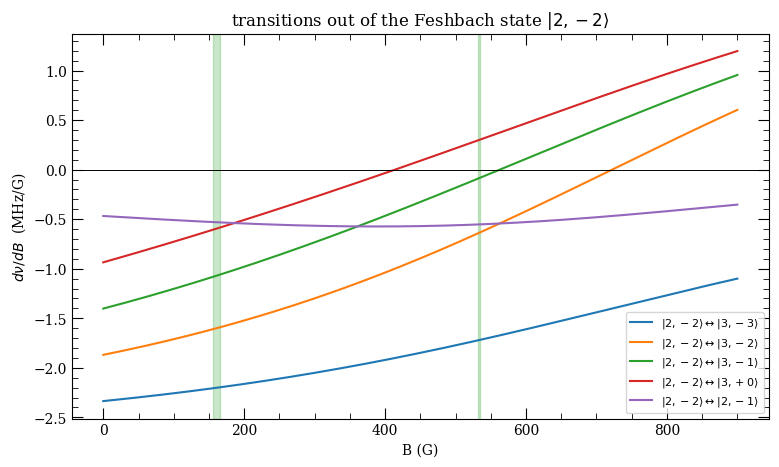

In [7]:
G = (5, 0, 0.5)

def track(s1, s2):
    return res.get_transition_frequency(G + s1, G + s2)

def sensitivity(s1, s2):
    return np.gradient(track(s1, s2), B)

candidates = [((2, -2), (3, -3)), ((2, -2), (3, -2)), ((2, -2), (3, -1)),
              ((2, -2), (3, 0)),  ((2, -2), (2, -1))]

fig, ax = plt.subplots(figsize=(9, 5))
for s1, s2 in candidates:
    ax.plot(B, sensitivity(s1, s2) / 1e6,
            label=rf"$|{s1[0]},{s1[1]:+d}\rangle \leftrightarrow |{s2[0]},{s2[1]:+d}\rangle$")
ax.axhline(0, color="k", lw=0.7)
for name, r in RESONANCES.items():
    if "ee" in name:
        lo, hi = sorted((r["B0"], r["B0"] + r["Delta"]))
        ax.axvspan(lo, hi, color="tab:green", alpha=0.25)
ax.set_xlabel("B (G)"); ax.set_ylabel(r"$d\nu/dB$  (MHz/G)")
ax.set_title("transitions out of the Feshbach state $|2,-2\\rangle$")
ax.legend(fontsize=8);

In [8]:
fields = [156.0, 160.0, 165.0, 533.0, 534.0]
hdr = "pair".ljust(24) + "".join(f"{b:>12.1f} G" for b in fields)
print(hdr); print("-" * len(hdr))
for s1, s2 in candidates:
    sens, f = sensitivity(s1, s2), np.abs(track(s1, s2))
    svals = np.interp(fields, B, sens)
    print(f"|{s1[0]},{s1[1]:+d}> <-> |{s2[0]},{s2[1]:+d}>".ljust(24)
          + "".join(f"{v/1e3:>11.1f} " for v in svals) + "  kHz/G")
    print(" " * 24 + "".join(f"{np.interp(b, B, f)/1e9:>11.4f} " for b in fields) + "  GHz  (frequency)")
print()
print("1 mG field noise -> qubit shift = sens * 1e-3 G:")
for s1, s2 in [((2, -2), (3, -3)), ((2, -2), (2, -1)), ((2, -2), (3, -1))]:
    for Bq in [160.0, 533.0]:
        v = np.interp(Bq, B, sensitivity(s1, s2))
        print(f"   |{s1[0]},{s1[1]:+d}> <-> |{s2[0]},{s2[1]:+d}>  at {Bq:5.0f} G: {v*1e-3:+8.1f} Hz/mG")

pair                           156.0 G       160.0 G       165.0 G       533.0 G       534.0 G
----------------------------------------------------------------------------------------------
|2,-2> <-> |3,-3>           -2205.6     -2201.8     -2197.0     -1720.6     -1719.0   kHz/G
                             2.6811      2.6722      2.6612      1.9331      1.9313   GHz  (frequency)
|2,-2> <-> |3,-2>           -1609.2     -1601.5     -1591.9      -639.1      -635.9   kHz/G
                             2.7635      2.7571      2.7491      2.3239      2.3233   GHz  (frequency)
|2,-2> <-> |3,-1>           -1080.9     -1071.9     -1060.6       -87.2       -84.3   kHz/G
                             2.8413      2.8370      2.8317      2.6130      2.6129   GHz  (frequency)
|2,-2> <-> |3,+0>            -605.6      -596.8      -585.7       298.5       301.0   kHz/G
                             2.9152      2.9128      2.9098      2.8532      2.8535   GHz  (frequency)
|2,-2> <-> |2,-1>            -

## 5. All the magic points — do any line up with a Feshbach window?

Same all-pairs scan as for Rb87 (zero crossings of $d\nu/dB$, 66 pairs of the
12 sublevels). Rb85's smaller hyperfine splitting pushes the intermediate
regime lower, so it has *many* magic points, including single-photon ones —
the interesting question is whether any fall where the BEC can live.

In [9]:
def magic_points(s1, s2, B_min=0.1):
    f, sens = track(s1, s2), sensitivity(s1, s2)
    curv = np.gradient(sens, B)
    i0 = np.searchsorted(B, B_min)
    out = []
    for i in np.where(np.diff(np.sign(sens[i0:])) != 0)[0] + i0:
        b0 = B[i] - sens[i] * (B[i + 1] - B[i]) / (sens[i + 1] - sens[i])
        out.append((b0, abs(f[i]), curv[i]))
    return out

states = sorted({res.convert_label(s)[3:] for s in model.states()})
rows = []
for s1, s2 in itertools.combinations(states, 2):
    for b0, f0, c in magic_points(s1, s2):
        rows.append((s1, s2, abs(s2[1] - s1[1]), b0, f0, c))

print(f"{'pair':<24}{'|dmF|':>6}{'B_magic (G)':>13}{'f (GHz)':>15}{'d2f/dB2 (Hz/G^2)':>19}")
for s1, s2, dmF, b0, f0, c in sorted(rows, key=lambda r: r[3]):
    print(f"|{s1[0]},{s1[1]:+d}> <-> |{s2[0]},{s2[1]:+d}>   {dmF:>5}{b0:>13.3f}{f0/1e9:>15.9f}{c:>19.1f}")

pair                     |dmF|  B_magic (G)        f (GHz)   d2f/dB2 (Hz/G^2)
|2,-1> <-> |3,+1>       2        0.357    3.035732292             2300.4
|2,-2> <-> |3,+2>       4        1.143    3.035731501             1437.8
|2,+0> <-> |3,-1>       1      185.663    2.992089857             2552.9
|2,-1> <-> |3,+0>       1      185.985    2.991937117             2552.9
|2,+1> <-> |3,-2>       3      243.226    2.978530635             1979.4
|2,-2> <-> |3,+1>       3      244.472    2.977929324             1980.2
|2,-1> <-> |3,-1>       0      361.020    2.862115992             2745.0
|2,+0> <-> |3,-2>       2      413.359    2.836237240             2469.9
|2,-2> <-> |3,+0>       2      414.025    2.835557155             2470.4
|2,-1> <-> |3,-2>       1      562.503    2.612113501             2935.2
|2,-2> <-> |3,-1>       1      562.783    2.611651027             2935.3
|2,-2> <-> |3,-2>       0      722.040    2.262701368             3472.1


Reading that table against the Feshbach windows:

* Rb85 has a direct analog of Rb87's famous 3.229 G pair: the two-photon
  $|2,-1\rangle \leftrightarrow |3,+1\rangle$ transition is magic at
  **0.357 G** (curvature 2300 Hz/G²). It sits at a 9× lower field than
  Rb87's because both $g_I$ and the hyperfine splitting are smaller. The
  $\Delta m_F = 4$ cousin $|2,-2\rangle \leftrightarrow |3,+2\rangle$
  (1.14 G) would need a four-photon drive.
* **Nothing magic in 155–165.8 G.** At the workhorse BEC field you simply pay
  the sensitivity of section 4. The nearest single-photon magic points
  ($|2,0\rangle \leftrightarrow |3,-1\rangle$ at 185.7 G and
  $|2,-1\rangle \leftrightarrow |3,0\rangle$ at 186.0 G) sit only 20 G above
  the window's upper edge — but at 186 G the scattering length is back to
  $\approx -290\,a_0$ and the condensate collapses.
* $|2,-2\rangle \leftrightarrow |3,-1\rangle$ is magic at **562.8 G** — a
  single-photon $\sigma^+$ microwave transition, and the 532 G window sits
  only 30 G below it, close enough that the sensitivity inside the window is
  already down to $\sim -87$ kHz/G (25× better than $|3,-3\rangle$ at
  160 G). But section 3 says this partner is **collisionally open**
  ($|2,-2\rangle{+}|3,-1\rangle \to$ two $F{=}2$ atoms, $-2.9$ GHz), and with
  Rb85's fast spin exchange that is likely fatal for a BEC-hosted qubit —
  fine for a thermal/dilute sample, worth a lifetime measurement before
  betting on it.
* The two-photon magic pair $|2,-2\rangle \leftrightarrow |3,0\rangle$
  (414.0 G) and the $\pi$ magic pair $|2,-2\rangle \leftrightarrow
  |3,-2\rangle$ (722.0 G) have no broad resonance anywhere near (604.1 G and
  854.3 G in this channel are milligauss-wide) — no BEC there.

## 6. The $|2,+2\rangle$ route

The 852.3 G resonance lives in the **absolute ground state**
$|2,+2\rangle$ — every two-body channel is endothermic, evaporation is free
of two-body loss, and the natural qubit partner is the doubly-stretched
$|3,+3\rangle$: the pair $|2,+2\rangle{+}|3,+3\rangle$ has
$m_{F,\mathrm{tot}} = +5$, unreachable from below, and its measured lifetime
($\sim$5 s, Blackley 2013) is the longest of any Rb85 spin mixture. The
price: the window is 1.2 G wide **below** 852.3 G, and the microwave
transition is nowhere near magic there ($+2.6$ MHz/G).

The quiet winner at this field is the **RF transition within the lower
manifold**, $|2,+2\rangle \leftrightarrow |2,+1\rangle$: at 852 G the field
is deep enough into the Breit–Rabi regime that both states head toward the
same $m_J = -1/2$ Paschen–Back branch, and the differential shift has fallen
to $\sim +0.18$ MHz/G — while staying fully closed (lower-manifold convexity
plus the stretched partner). That is the least field-sensitive **closed**
qubit at any field where an Rb85 BEC can live.

In [10]:
aa_pairs = [((2, 2), (3, 3)), ((2, 2), (3, 2)), ((2, 2), (2, 1))]
for combo in [((2, 2), (2, 2)), ((2, 2), (3, 3)), ((3, 3), (3, 3)),
              ((2, 1), (2, 2)), ((2, 1), (2, 1))]:
    ex = closed_report(combo, 852.0)
    print(f"{combo[0]}+{combo[1]} at 852 G:", "closed" if not ex else f"OPEN ({len(ex)} exits)")
print()
for s1, s2 in aa_pairs:
    v = np.interp(852.0, B, sensitivity(s1, s2))
    f = np.interp(852.0, B, np.abs(track(s1, s2)))
    print(f"|{s1[0]},{s1[1]:+d}> <-> |{s2[0]},{s2[1]:+d}>  at 852 G: "
          f"f = {f/1e9:.4f} GHz, sens = {v/1e6:+.3f} MHz/G")

(2, 2)+(2, 2) at 852 G: closed
(2, 2)+(3, 3) at 852 G: closed
(3, 3)+(3, 3) at 852 G: closed
(2, 1)+(2, 2) at 852 G: closed
(2, 1)+(2, 1) at 852 G: closed

|2,+2> <-> |3,+3>  at 852 G: f = 5.1907 GHz, sens = +2.648 MHz/G
|2,+2> <-> |3,+2>  at 852 G: f = 4.9583 GHz, sens = +2.494 MHz/G
|2,+2> <-> |2,+1>  at 852 G: f = 0.2574 GHz, sens = +0.175 MHz/G


## 7. Summary

Where a Rb85 BEC can live, and the best qubit at each field:

| Feshbach window | BEC state | best **closed** partner | drive | $d\nu/dB$ there | tempting but open |
|---|---|---|---|---|---|
| 155.0–165.8 G (the JILA resonance) | $\|2,-2\rangle$ | $\|3,-3\rangle$ (−2.20 MHz/G) or $\|2,-1\rangle$ (−0.53 MHz/G, 80 MHz RF) | 1 photon | 0.5–2.2 MHz/G | $\|3,-1\rangle$, $\|3,0\rangle$ (smaller sens., open) |
| 532.3–534.6 G | $\|2,-2\rangle$ | $\|2,-1\rangle$ (−0.55 MHz/G) | RF | 0.55 MHz/G | $\|3,-1\rangle$: −87 kHz/G (magic at 562.8 G!) but spin-exchange open |
| 851.1–852.3 G | $\|2,+2\rangle$ (absolute ground state) | $\|2,+1\rangle$ (**+0.18 MHz/G**) or $\|3,+3\rangle$ (stretched, ~5 s measured, +2.65 MHz/G) | RF / 1 photon $\sigma^+$ | 0.18–2.65 MHz/G | — |

Take-aways:

* **No free lunch at 155 G**: every closed qubit there carries
  $\gtrsim 0.5$ MHz/G, so 1 mG of field control costs $\gtrsim 500$ Hz. Field
  stability, not the choice of pair, is the coherence budget.
* The best closed-qubit sensitivity anywhere a Rb85 BEC exists is the
  852 G window's RF pair $|2,+2\rangle \leftrightarrow |2,+1\rangle$ at
  $+0.18$ MHz/G — three times better than anything at 155 G, in the absolute
  ground state, at the cost of a 1.2 G-wide window at high field.
* The **532 G window + $|2,-2\rangle \leftrightarrow |3,-1\rangle$** is the
  one genuinely interesting loophole: near-magic (−87 kHz/G, heading to zero
  at 562.8 G) and single-photon, at the cost of an energetically open
  spin-exchange channel — a measurement of its inelastic rate would decide.
* Beyond field noise, a BEC-hosted qubit also has a **density (mean-field)
  shift** $\propto n\,(a_{bb} + a_{ab} - a_{aa} - a_{ab}')$: with
  $a_{aa}$ Feshbach-tuned and the partner's lengths at background
  ($\approx -400\,a_0$), the differential is large and *tunes with the same
  field* you use to stabilize the BEC. Three-body loss also grows steeply
  toward the pole ($a \gtrsim 1000\,a_0$). Neither is computed here —
  they need coupled-channels input that `kamo.scattering` only has for K39.